In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, exposure
from skimage.exposure import match_histograms

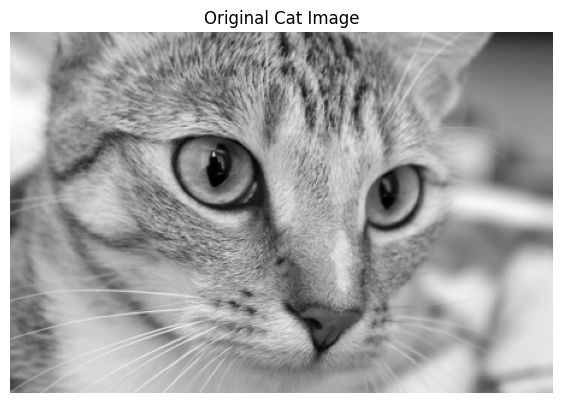

In [17]:
cat_color = data.chelsea()

img = cv2.cvtColor(cat_color, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(7, 5))
plt.imshow(img, cmap="gray")
plt.title("Original Cat Image")
plt.axis("off")
plt.show()

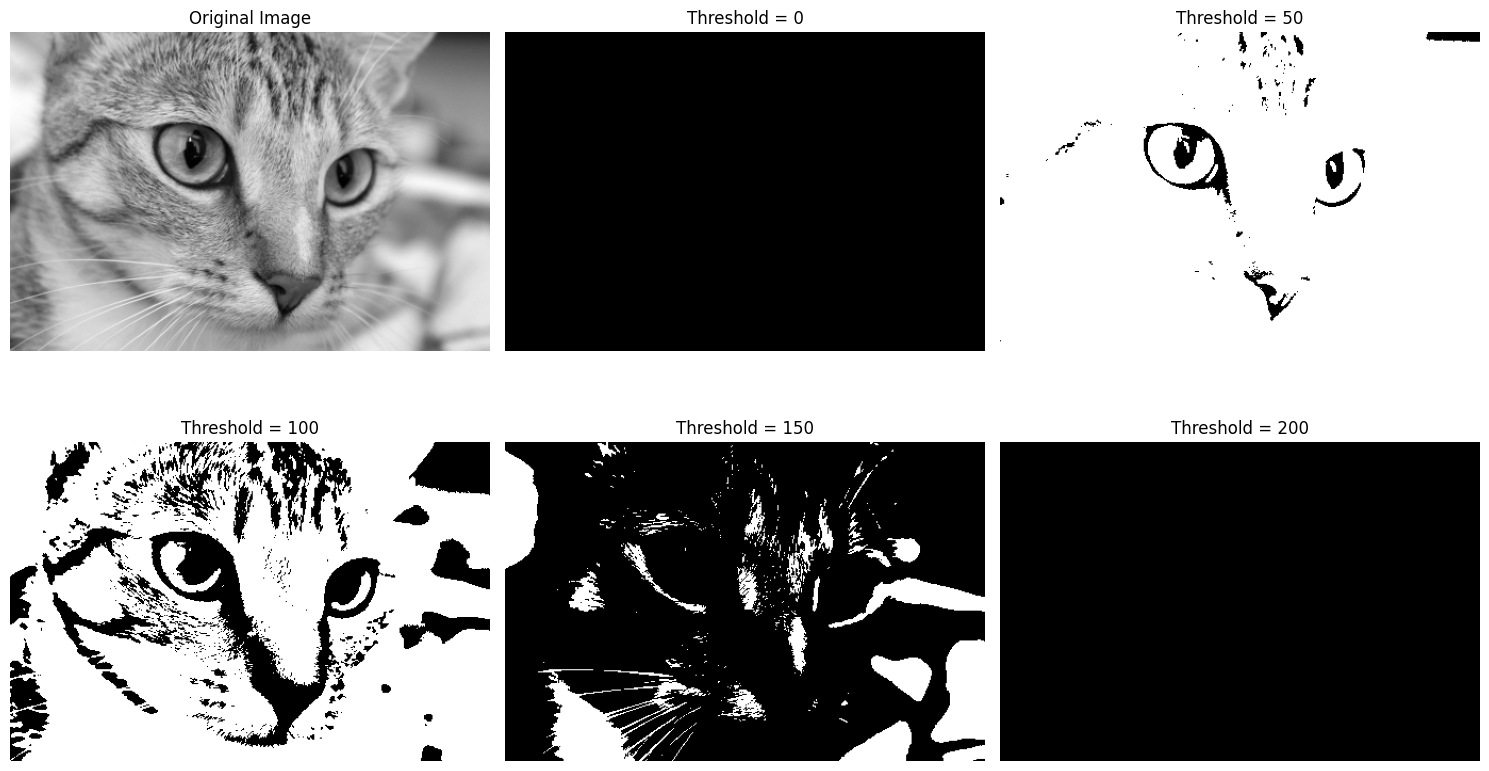

In [18]:
threshold_values = [0, 50, 100, 150, 200]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(img, cmap="gray")
axes[0, 0].set_title("Original Image")
axes[0, 0].axis("off")

for ax, threshold_value in zip(axes.flat[1:], threshold_values):
    ret, thresh = cv2.threshold(
        img,
        threshold_value,
        255,
        cv2.THRESH_BINARY
    )

    ax.imshow(thresh, cmap="gray")
    ax.set_title(f"Threshold = {threshold_value}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Image shape: (512, 512)
Minimum intensity: 0
Maximum intensity: 255


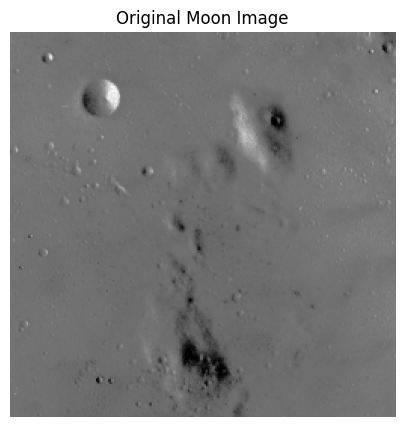

In [19]:
moon_img = data.moon()

print("Image shape:", moon_img.shape)
print("Minimum intensity:", moon_img.min())
print("Maximum intensity:", moon_img.max())

plt.figure(figsize=(7, 5))
plt.imshow(moon_img, cmap="gray")
plt.title("Original Moon Image")
plt.axis("off")
plt.show()

In [20]:
p2, p98 = np.percentile(moon_img, (2, 98))

moon_rescaled = exposure.rescale_intensity(
    moon_img,
    in_range=(p2, p98)
)

print("2nd percentile:", p2)
print("98th percentile:", p98)

2nd percentile: 78.0
98th percentile: 129.0


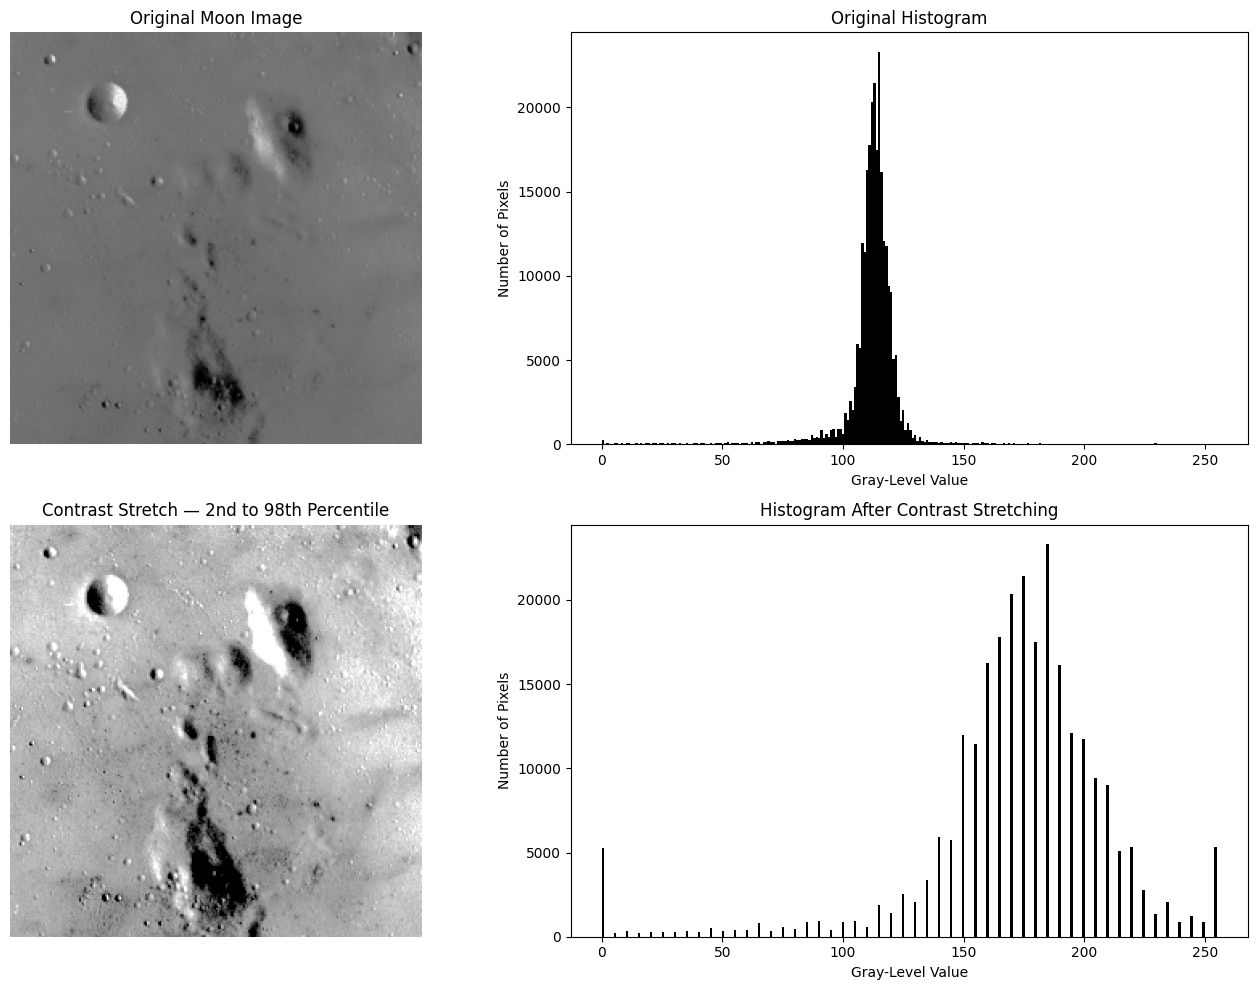

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].imshow(moon_img, cmap="gray")
axes[0, 0].set_title("Original Moon Image")
axes[0, 0].axis("off")

axes[0, 1].hist(
    moon_img.ravel(),
    bins=256,
    range=(0, 255),
    color="black"
)
axes[0, 1].set_title("Original Histogram")
axes[0, 1].set_xlabel("Gray-Level Value")
axes[0, 1].set_ylabel("Number of Pixels")

axes[1, 0].imshow(moon_rescaled, cmap="gray")
axes[1, 0].set_title("Contrast Stretch — 2nd to 98th Percentile")
axes[1, 0].axis("off")

axes[1, 1].hist(
    moon_rescaled.ravel(),
    bins=256,
    range=(0, 255),
    color="black"
)
axes[1, 1].set_title("Histogram After Contrast Stretching")
axes[1, 1].set_xlabel("Gray-Level Value")
axes[1, 1].set_ylabel("Number of Pixels")

plt.tight_layout()
plt.show()

3rd percentile: 87.0
80th percentile: 118.0


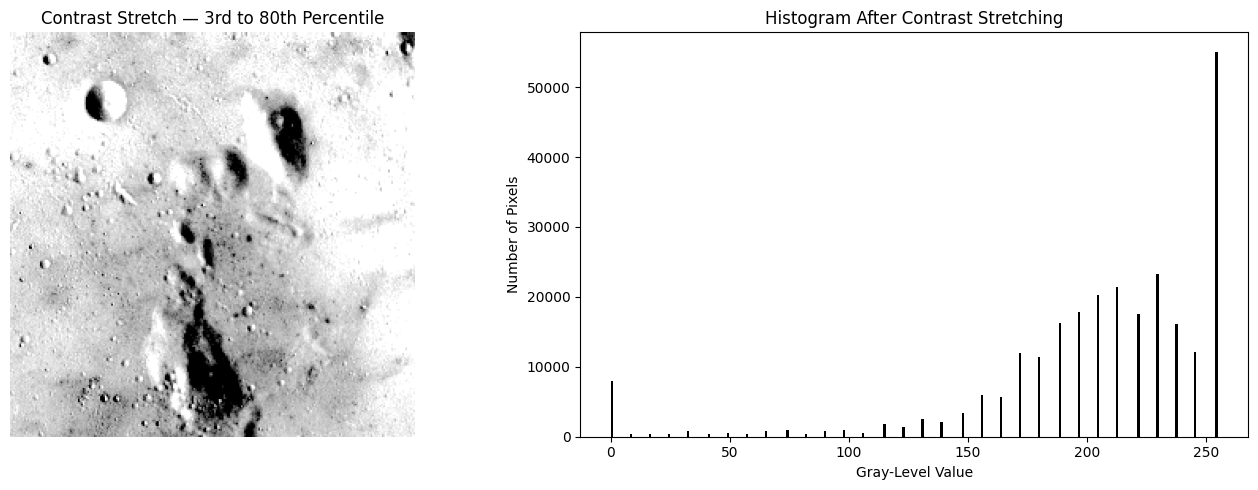

In [22]:
p3, p80 = np.percentile(moon_img, (3, 80))
moon_rescaled_3_80 = exposure.rescale_intensity(
    moon_img,
    in_range=(p3, p80)
)

print("3rd percentile:", p3)
print("80th percentile:", p80)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(moon_rescaled_3_80, cmap="gray")
axes[0].set_title("Contrast Stretch — 3rd to 80th Percentile")
axes[0].axis("off")

axes[1].hist(
    moon_rescaled_3_80.ravel(),
    bins=256,
    range=(0, 255),
    color="black"
)
axes[1].set_title("Histogram After Contrast Stretching")
axes[1].set_xlabel("Gray-Level Value")
axes[1].set_ylabel("Number of Pixels")

plt.tight_layout()
plt.show()

Minimum intensity: 0.00091552734375
Maximum intensity: 1.0


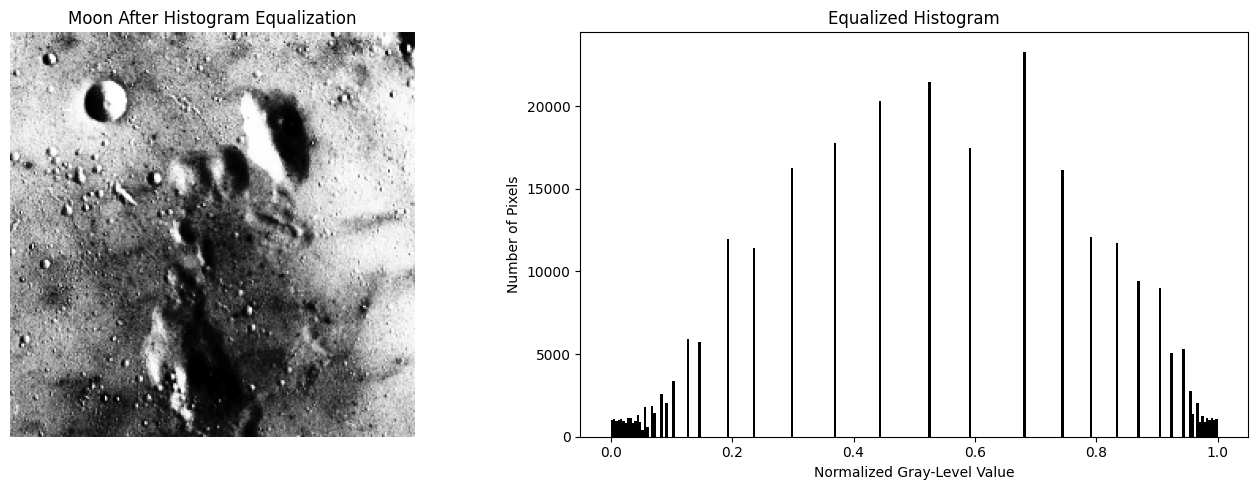

In [23]:
moon_equalized = exposure.equalize_hist(moon_img)

print("Minimum intensity:", moon_equalized.min())
print("Maximum intensity:", moon_equalized.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(moon_equalized, cmap="gray")
axes[0].set_title("Moon After Histogram Equalization")
axes[0].axis("off")

axes[1].hist(
    moon_equalized.ravel(),
    bins=256,
    range=(0, 1),
    color="black"
)
axes[1].set_title("Equalized Histogram")
axes[1].set_xlabel("Normalized Gray-Level Value")
axes[1].set_ylabel("Number of Pixels")

plt.tight_layout()
plt.show()

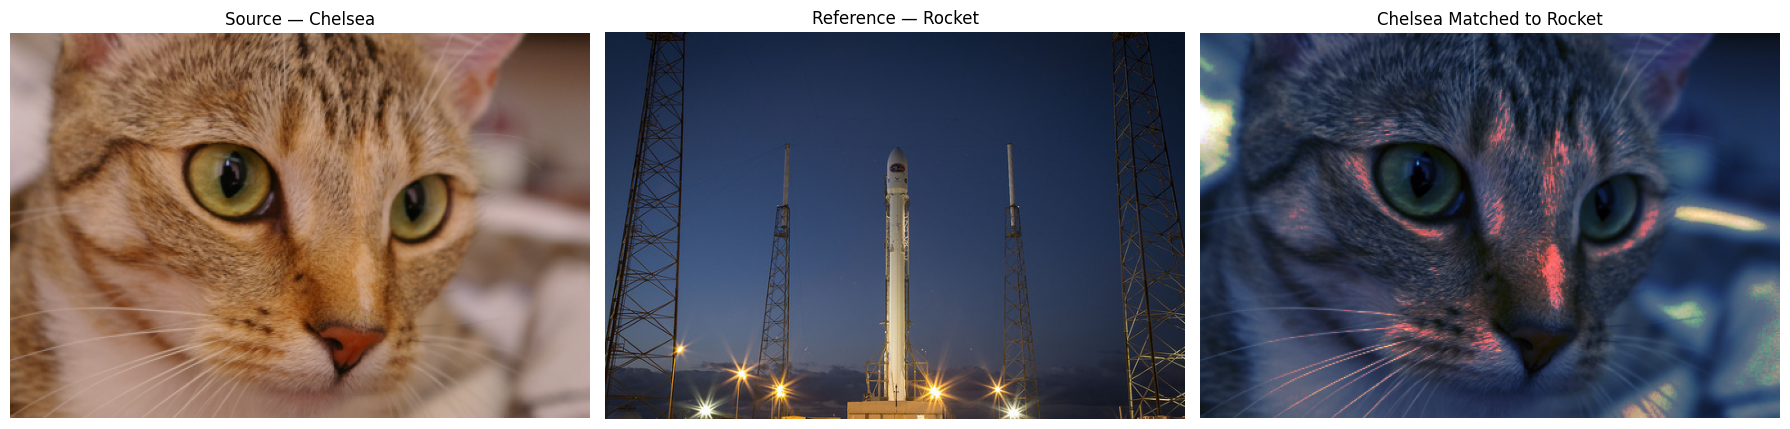

In [24]:
chelsea_img = data.chelsea()
rocket_img = data.rocket()

matched_img = match_histograms(
    chelsea_img,
    rocket_img,
    channel_axis=-1
)

matched_display = np.clip(matched_img, 0, 255).astype(np.uint8)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(chelsea_img)
axes[0].set_title("Source — Chelsea")
axes[0].axis("off")

axes[1].imshow(rocket_img)
axes[1].set_title("Reference — Rocket")
axes[1].axis("off")

axes[2].imshow(matched_display)
axes[2].set_title("Chelsea Matched to Rocket")
axes[2].axis("off")

plt.tight_layout()
plt.show()

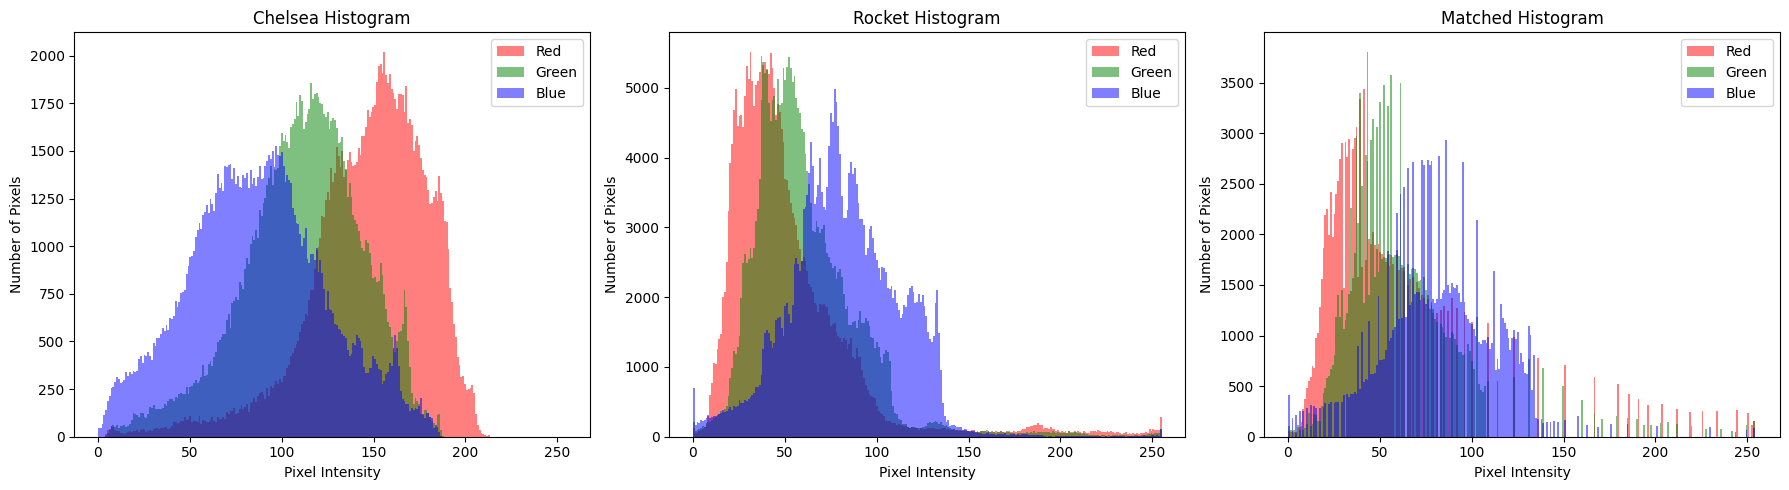

In [25]:
images = [
    chelsea_img,
    rocket_img,
    matched_display
]

titles = [
    "Chelsea Histogram",
    "Rocket Histogram",
    "Matched Histogram"
]

colors = ["red", "green", "blue"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, image, title in zip(axes, images, titles):
    for channel, color in enumerate(colors):
        ax.hist(
            image[:, :, channel].ravel(),
            bins=256,
            range=(0, 255),
            color=color,
            alpha=0.5,
            label=color.capitalize()
        )

    ax.set_title(title)
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Number of Pixels")
    ax.legend()

plt.tight_layout()
plt.show()